In [10]:

print("Họ tên: PhanCongTri")
print("Mã số sinh viên: 6451071080")

# Linear algebra
import numpy as np

# Data processing
import pandas as pd

# Data visualization
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib import style

# Đọc dữ liệu đã xử lý từ file tb_tracking_processed.csv
df = pd.read_csv(
    'tb_tracking_processed.csv',
    parse_dates=['time']
)


Họ tên: PhanCongTri
Mã số sinh viên: 6451071080


In [11]:
print("Họ tên: PhanCongTri")
print("Mã số sinh viên: 6451071080")

# 2. Lọc bỏ dữ liệu trước ngày 03/01/2018 theo yêu cầu
df['datetime'] = pd.to_datetime(df['time'], errors='coerce', format='mixed')
df = df[df['datetime'] >= '2018-01-03']

# 3. Chuyển đổi logic tương đương cho file tb_tracking
for dataset in [df]:
    # Tạo chỉ số tổng hợp tương đương từ humidity và temperature (hoặc các cột tương ứng)
    dataset['metric_sum'] = dataset['humidity'] + dataset['temperature']
    
    # Phân loại trạng thái dựa trên điều kiện giá trị
    dataset.loc[dataset['metric_sum'] > 50, 'not_alone'] = 0
    dataset.loc[dataset['metric_sum'] <= 50, 'not_alone'] = 1
    
    # Ép kiểu dữ liệu sang int
    dataset['not_alone'] = dataset['not_alone'].astype(int)

# Kiểm tra kết quả phân loại thống kê
print(df['not_alone'].value_counts())

Họ tên: PhanCongTri
Mã số sinh viên: 6451071080
not_alone
0    1890
1      27
Name: count, dtype: int64


Họ tên: PhanCongTri
Mã số sinh viên: 6451071080


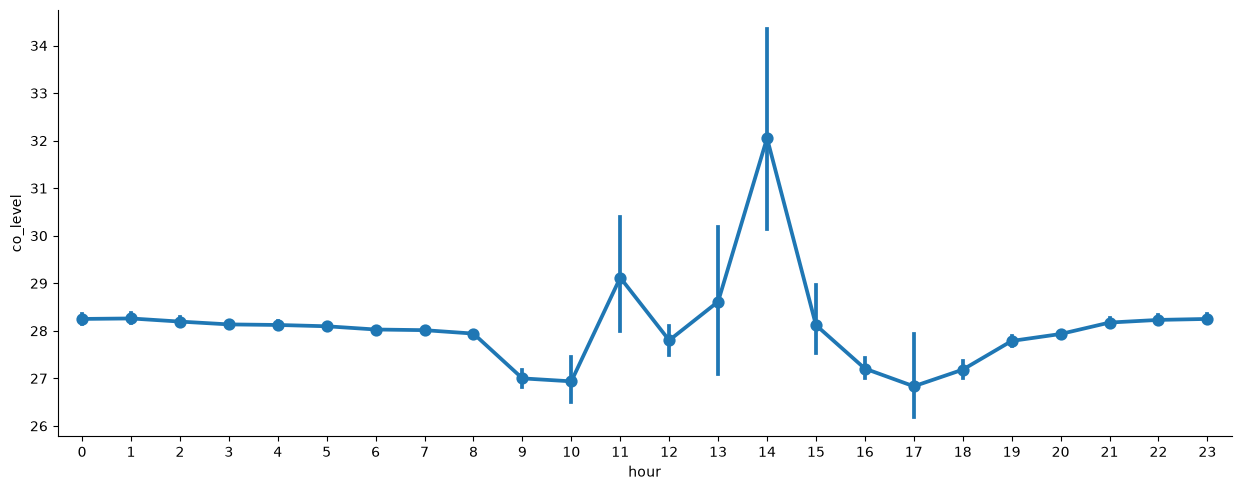

In [12]:
print("Họ tên: PhanCongTri")
print("Mã số sinh viên: 6451071080")

# Tạo cột 'hour' từ cột 'time' để có thể truyền vào x='hour'
df['hour'] = df['time'].dt.hour

axes = sns.catplot(
    x='hour',
    y='co_level',
    data=df,
    aspect=2.5,
    kind='point'
)